# Supplementary Figure S3. FastRNA's ambiguous pairs

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

import hashlib
import inspect
import pickle
from functools import lru_cache

REFRESH = False
CACHE_DIR = ROOT / ".cache" / "figS3"


def _input_key():
    h = hashlib.sha1()
    for path in sorted(data_file("comparison").rglob("*")):
        if path.is_file():
            st = path.stat()
            h.update(f"{path.relative_to(ROOT)}|{st.st_size}|{st.st_mtime_ns}".encode())
    return h.hexdigest()[:12]


INPUT_KEY = _input_key()


def disk_cache(fn):
    try:
        src = inspect.getsource(fn)
    except (OSError, TypeError):
        src = fn.__code__.co_code.hex()
    path = CACHE_DIR / f"{fn.__name__}-{INPUT_KEY}-{hashlib.sha1(src.encode()).hexdigest()[:8]}.pkl"

    @lru_cache(maxsize=1)
    def wrapper():
        if path.exists() and not REFRESH:
            return pickle.loads(path.read_bytes())
        out = fn()
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        path.write_bytes(pickle.dumps(out))
        return out
    return wrapper


def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

CUT = 80.0

LW = ["cWW", "tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
TOOLS = ["parse", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["FastRNA", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNET"]

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_parse.jsonl"), lines=True)

def scored_pairs(lw_only=True) -> pd.DataFrame:
    df = pair_scores()
    df = df[~df["is_ambiguous"].fillna(False) & df["score"].notna()].copy()
    return df[df["lw_class"].isin(LW)].copy() if lw_only else df

def _resolution(m):
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (Å)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (Å)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({"pdb": pdb, "pairs_score": info.get("pairs_score"),
                     "backbone_suiteness": info.get("backbone_suiteness"),
                     "n_pairs": info.get("n_pairs", 0),
                     "n_residues_scored": info.get("n_residues_scored", 0),
                     "method": m.get("Experimental_method"),
                     "resolution": _resolution(m), "clashscore": m.get("clashscore"),
                     "rnasuiteness": m.get("rnasuiteness"),
                     "n_nucleotides": nt.get(pdb),
                     "deposited": m.get("Deposition_Date")})
    return pd.DataFrame(rows)

def runtime() -> pd.DataFrame:
    df = pd.read_csv(data_file("benchmark/dssr_PARSE_time_benchmark.csv"))
    df = df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["parse_avg"] > 0)].copy()
    df["ratio"] = df["dssr_avg"] / df["parse_avg"]
    return df

WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUES = list(WEIGHTS)
ISSUE_LABELS = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}

def hist_grid(fig, spec, df, params, xlabel, cols=3):
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.42, hspace=0.62)
    axes = []
    for i, p in enumerate(params):
        ax = fig.add_subplot(sub[i // cols, i % cols])
        vals = pd.to_numeric(df[p], errors="coerce").dropna()
        if len(vals) > 20000:
            vals = vals.sample(20000, random_state=1)
        ax.hist(vals, bins=40, color=BLUE, alpha=0.8)
        ax.set_xlabel(p.replace("_", " "), fontsize=7.5)
        ax.tick_params(labelsize=6.5)
        if i % cols == 0:
            ax.set_ylabel("Count", fontsize=7.5)
        finish(ax)
        axes.append(ax)
    return axes

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


## Shared tool-comparison helpers

In [2]:
from functools import lru_cache
from itertools import combinations
from matplotlib.colors import Normalize


def _heatmap(ax, matrix, label, vmin, vmax, fig=None, cax=None):
    cmap = plt.cm.Blues.copy()
    cmap.set_bad("0.90")
    im = ax.imshow(matrix.to_numpy(float), cmap=cmap, norm=Normalize(vmin, vmax))
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    finish(ax)
    ax.tick_params(length=0)
    hi = vmin + 0.62 * (vmax - vmin)
    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            v = matrix.iat[r, c]
            if np.isnan(v):
                ax.text(c, r, "n/a", ha="center", va="center", fontsize=6, color="0.40")
            else:
                ax.text(c, r, "1" if v >= 0.995 else f"{v:.2f}"[1:], ha="center",
                        va="center", fontsize=6, color="white" if v > hi else "0.15")
    if cax is not None:
        p = cax.get_position()
        horizontal = p.width * (fig or ax.figure).get_size_inches()[0] > \
            p.height * (fig or ax.figure).get_size_inches()[1]
        cb = (fig or ax.figure).colorbar(im, cax=cax,
                                         orientation="horizontal" if horizontal else "vertical")
        if horizontal:
            cax.xaxis.set_ticks_position("top")
            cax.xaxis.set_label_position("top")
    else:
        cb = (fig or ax.figure).colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label(label)
    cb.outline.set_visible(False)
    return im

MATRIX_TOOLS = ["parse", "dssr", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
MATRIX_LABELS = ["FastRNA", "DSSR", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNET"]
JSON_PAIR_FILES = {
    "parse": "comparison/parse_pairs.json",
    "dssr": "comparison/dssr_pairs.json",
    "rnaview": "comparison/rnaview_pairs.json",
    "barnaba": "comparison/barnaba_pairs.json",
    "rnapolis": "comparison/rnapolis_pairs.json",
    "bpnet": "comparison/bpnet_pairs.json",
}
_NUM = __import__("re").compile(r"^(-?\d+)([A-Za-z]?)$")
UNCLASSIFIED = "?"


def _residue(chain, number, icode=""):
    m = _NUM.match(str(number))
    if not chain or m is None:
        raise ValueError(f"uncanonicalizable residue id: {chain!r} {number!r}")
    appended = m.group(2)
    if appended and icode:
        raise ValueError(f"two insertion codes: {chain!r} {number!r} {icode!r}")
    return (str(chain), int(m.group(1)), icode or appended)


def _flip(lw):
    if lw == UNCLASSIFIED:
        return lw
    if lw.startswith("n"):
        return "n" + _flip(lw[1:])
    if len(lw) != 3:
        return lw
    return lw[0] + lw[2] + lw[1]


def _flip_label(label):
    return "|".join(_flip(part) for part in label.split("|"))


def _pair_entry(res1, res2, label):
    if res2 < res1:
        return (res2, res1), _flip_label(label)
    return (res1, res2), label


def _adjacent(res1, res2):
    return res1[0] == res2[0] and abs(res1[1] - res2[1]) == 1


def _ingest(rows):
    pairs = {}
    for res1, res2, label in rows:
        if _adjacent(res1, res2):
            continue
        key, canonical_label = _pair_entry(res1, res2, label)
        pairs.setdefault(key, set()).add(canonical_label)
    return pairs


def _load_json_pairs(tool):
    raw = _json(JSON_PAIR_FILES[tool])
    out = {}
    for pdb, record in raw.items():
        if record.get("status") != "ok":
            continue
        rows = []
        for row in record["pairs"]:
            c1, n1, c2, n2, lw = row[:5]
            rows.append((_residue(c1, n1), _residue(c2, n2), lw or UNCLASSIFIED))
        out[pdb] = _ingest(rows)
    return out


def _hub_unit(unit):
    fields = unit.split("|")
    if len(fields) < 5 or fields[1] != "1":
        return None
    icode = fields[7] if len(fields) >= 8 else ""
    return _residue(fields[2], fields[4], icode)


def _load_fr3d_pairs():
    out = {}
    for csv_path in sorted(data_file("comparison/fr3d").glob("[0-9A-Z]*.csv")):
        rows = []
        for line in csv_path.read_text(errors="replace").splitlines():
            if not line.strip():
                continue
            fields = [part.strip().strip('"') for part in line.split('\",\"')]
            if len(fields) != 3:
                continue
            res1, res2 = _hub_unit(fields[0]), _hub_unit(fields[2])
            if res1 is not None and res2 is not None:
                rows.append((res1, res2, fields[1]))
        out[csv_path.stem] = _ingest(rows)
    return out


@lru_cache(maxsize=1)
def _load_all_pairsets():
    pairsets = {tool: _load_json_pairs(tool) for tool in JSON_PAIR_FILES}
    pairsets["fr3d"] = _load_fr3d_pairs()
    return pairsets


def _single_family(labels):
    if any("|" in lw for lw in labels):
        return None
    fams = {lw for lw in labels if len(lw) == 3 and lw[0] in "ct"
            and lw[1] in "WHS" and lw[2] in "WHS"}
    return next(iter(fams)) if len(fams) == 1 else None


def _single_family_units(pairsets_by_pdb):
    units = {}
    for pdb, pairsets in pairsets_by_pdb.items():
        for key, labels in pairsets.items():
            fam = _single_family(labels)
            if fam is not None:
                units[(pdb, key)] = fam
    return units


def _canon_lw(lw):
    order = {"W": 0, "H": 1, "S": 2}
    return lw[0] + lw[2] + lw[1] if order[lw[1]] > order[lw[2]] else lw


WATSON_CRICK = {frozenset("GC"), frozenset("AU")}


@lru_cache(maxsize=1)
def _residue_names():
    return _json("comparison/residue_names.json")


def _is_canonical(pdb, key, labels):
    names = _residue_names().get(pdb, {})
    bases = [names.get(f"{chain}|{num}|{icode}") for chain, num, icode in key]
    if None in bases or frozenset(bases) not in WATSON_CRICK:
        return False
    return any(part == "cWW" for lw in labels for part in lw.split("|"))


@lru_cache(maxsize=1)
def _parse_candidates():
    raw = _json("comparison/parse_candidates.json")
    return {pdb: _ingest([(_residue(c1, n1), _residue(c2, n2), lw or UNCLASSIFIED)
                          for c1, n1, c2, n2, lw, _ in rec["pairs"]])
            for pdb, rec in raw.items() if pdb != "_meta"}


@lru_cache(maxsize=None)
def fastrna_credited(partner):
    pairsets, candidates = _load_all_pairsets(), _parse_candidates()
    out = {}
    for pdb, ours in pairsets["parse"].items():
        theirs = pairsets[partner].get(pdb, {})
        extra = {k: v for k, v in candidates.get(pdb, {}).items()
                 if k in theirs and k not in ours and UNCLASSIFIED not in v}
        out[pdb] = {**ours, **extra}
    return out


def _pair_lists(a, b):
    pairsets = _load_all_pairsets()
    pa = fastrna_credited(b) if a == "parse" else pairsets[a]
    pb = fastrna_credited(a) if b == "parse" else pairsets[b]
    return pa, pb


def _empty_matrix():
    return pd.DataFrame(np.eye(len(MATRIX_LABELS)), index=MATRIX_LABELS, columns=MATRIX_LABELS)


@disk_cache
def noncanonical_detection_matrix():
    pairsets = _load_all_pairsets()
    mat = _empty_matrix()
    for (a, la), (b, lb) in combinations(zip(MATRIX_TOOLS, MATRIX_LABELS), 2):
        inter = union = 0
        list_a, list_b = _pair_lists(a, b)
        for pdb in list_a.keys() & list_b.keys():
            pa, pb = list_a[pdb], list_b[pdb]
            for key in pa.keys() | pb.keys():
                labels = pa.get(key, set()) | pb.get(key, set())
                if any("|" in lw for lw in labels) or _is_canonical(pdb, key, labels):
                    continue
                union += 1
                inter += key in pa and key in pb
        mat.loc[la, lb] = mat.loc[lb, la] = inter / union
    return mat


@disk_cache
def noncanonical_kappa_matrix():
    pairsets = _load_all_pairsets()
    units = {tool: _single_family_units(pairsets[tool]) for tool in MATRIX_TOOLS}
    mat = _empty_matrix()
    for (a, la), (b, lb) in combinations(zip(MATRIX_TOOLS, MATRIX_LABELS), 2):
        n = agree = 0
        c1, c2 = Counter(), Counter()
        list_a, list_b = _pair_lists(a, b)
        ua = units[a] if a != "parse" else _single_family_units(list_a)
        ub = units[b] if b != "parse" else _single_family_units(list_b)
        for (pdb, key), x in ua.items():
            y = ub.get((pdb, key))
            if y is None or _is_canonical(pdb, key, {x, y}):
                continue
            n += 1
            agree += x == y
            c1[x] += 1
            c2[y] += 1
        po, pe = agree / n, sum(c1[k] * c2[k] for k in c1) / n ** 2
        mat.loc[la, lb] = mat.loc[lb, la] = (po - pe) / (1 - pe)
    return mat


## Panels A and B
FastRNA's ambiguous pairs are the pairs the other tools disagree on: overall (A) and per ambiguity type (B)

3,843 ambiguous and 748,260 unambiguous FastRNA pairs in 1,177 structures


,flagged (%),confident (%),bootstrap p,P (cluster-robust),significance
comparison,,,,,
all ambiguous vs family-matched,54.692892,23.800773,< 0.0005,1.211441e-244,****
cHH|cWW,42.691415,24.880942,< 0.0005,8.659346e-22,****
tHH|tWW,67.682927,25.133738,< 0.0005,1.988928e-76,****
cHH|cWH,70.813397,32.022880,< 0.0005,3.927222e-58,****
tHH|tWH,55.942029,28.811854,< 0.0005,6.493023e-24,****
cWH|cWW,39.184953,8.049559,< 0.0005,8.586905e-30,****
tWH|tWW,51.324503,13.314884,< 0.0005,1.779957e-42,****


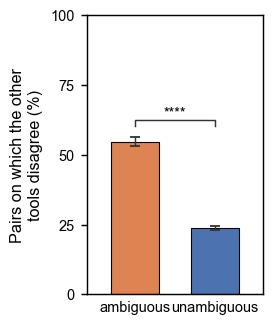

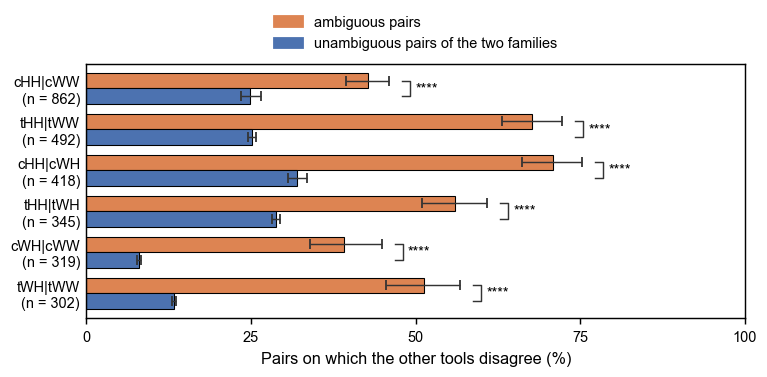

In [3]:
from collections import Counter
canon = _canon_lw
OTHER = ["dssr", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]

def family(labels):
    fams = {canon(lw) for lw in labels if len(lw) == 3 and lw[0] in "ct"
            and lw[1] in "WHS" and lw[2] in "WHS"}
    return next(iter(fams)) if len(fams) == 1 else None

@disk_cache
def votes_table():
    pairsets = _load_all_pairsets()
    rows = []
    for pdb, pairs in pairsets["parse"].items():
        for key, labels in pairs.items():
            amb = [lw for lw in labels if "|" in lw]
            own = None if amb else family(labels)
            if not amb and own is None:
                continue
            opts = tuple(sorted({canon(x) for x in amb[0].split("|")})) if amb else None
            votes = {t: f for t in OTHER
                     if (lab := pairsets[t].get(pdb, {}).get(key)) is not None
                     and (f := family(lab)) is not None}
            rows.append((pdb, bool(amb), own, opts, votes))
    return pd.DataFrame(rows, columns=["pdb", "amb", "own", "opts", "votes"])


V = votes_table().copy()
V["k"] = V.votes.map(len)
V["split"] = V.votes.map(lambda v: len(set(v.values())) > 1)
print(f"{V.amb.sum():,} ambiguous and {(~V.amb).sum():,} unambiguous FastRNA pairs in "
      f"{V.pdb.nunique():,} structures")

E = V[V.k >= 2].reset_index(drop=True)

B_REPS = 2000
pdb_idx, pdbs = pd.factorize(E.pdb)
nP = len(pdbs)

def counts(mask):
    m = np.asarray(mask)
    return (np.bincount(pdb_idx[m], weights=E.split.to_numpy()[m].astype(float), minlength=nP),
            np.bincount(pdb_idx[m], minlength=nP).astype(float))

UN_FAM = {f: counts((~E.amb) & (E.own == f)) for f in E.loc[~E.amb, "own"].unique()}
AMB_TYPES = [o for o, _ in Counter(E[E.amb].opts).most_common(6)]
AMB_T = {o: counts(E.amb & (E.opts == o)) for o in AMB_TYPES}
ALL_AMB, ALL_UN = counts(E.amb), counts(~E.amb)
W_ALL = Counter()
for o in E[E.amb].opts:
    for f in o:
        W_ALL[f] += 1 / len(o)

def matched(w, weights):
    r = {f: (w @ UN_FAM[f][0]) / (w @ UN_FAM[f][1]) for f in weights if f in UN_FAM}
    return sum(r[f] * weights[f] for f in r) / sum(weights[f] for f in r)

def stats(w):
    out = {"all_amb": (w @ ALL_AMB[0]) / (w @ ALL_AMB[1]), "all_un": (w @ ALL_UN[0]) / (w @ ALL_UN[1]),
           "all_matched": matched(w, W_ALL)}
    for o in AMB_TYPES:
        out[("amb", o)] = (w @ AMB_T[o][0]) / (w @ AMB_T[o][1])
        out[("mat", o)] = matched(w, {f: 0.5 for f in o})
    return out

POINT2 = stats(np.ones(nP))
rng = np.random.default_rng(7)
BS = pd.DataFrame([stats(np.bincount(rng.integers(0, nP, nP), minlength=nP).astype(float))
                   for _ in range(B_REPS)])

def ci(k):
    return BS[k].quantile(0.025), BS[k].quantile(0.975)

def pval(a, b):
    d = BS[a] - BS[b]
    p = 2 * min((d <= 0).mean(), (d >= 0).mean())
    return max(p, 1 / B_REPS)

def stars(p):
    return ("****" if p < 0.0001 else "***" if p < 0.001 else "**" if p < 0.01
            else "*" if p < 0.05 else "n.s.")

from scipy.stats import norm

def cluster_p(weights, amb_counts):
    fams = [f for f in weights if f in UN_FAM]
    wsum = sum(weights[f] for f in fams)
    d_a, n_a = amb_counts
    r_a = d_a.sum() / n_a.sum()
    diff = r_a
    u = (d_a - r_a * n_a) / n_a.sum()
    for f in fams:
        d_f, n_f = UN_FAM[f]
        r_f = d_f.sum() / n_f.sum()
        wf = weights[f] / wsum
        diff -= wf * r_f
        u -= wf * (d_f - r_f * n_f) / n_f.sum()
    G = len(u)
    se = np.sqrt(G / (G - 1) * (u ** 2).sum())
    return 2 * norm.sf(abs(diff / se))

def p_text(p):
    if p < 1e-300:
        return "P < 10$^{-300}$"
    m, e = f"{p:.1e}".split("e")
    return f"P = {p:.2g}" if p >= 1e-3 else f"P = {m} × 10$^{{{int(e)}}}$"

rows = [{"comparison": "all ambiguous vs family-matched", "flagged (%)": 100 * POINT2["all_amb"],
         "confident (%)": 100 * POINT2["all_matched"], "p": pval("all_amb", "all_matched"),
         "P (cluster-robust)": cluster_p(dict(W_ALL), ALL_AMB)}]
for o in AMB_TYPES:
    rows.append({"comparison": "|".join(o), "flagged (%)": 100 * POINT2[("amb", o)],
                 "confident (%)": 100 * POINT2[("mat", o)], "p": pval(("amb", o), ("mat", o)),
                 "P (cluster-robust)": cluster_p({f: 0.5 for f in o}, AMB_T[o])})
SIG = pd.DataFrame(rows).set_index("comparison")
SIG["significance"] = SIG["P (cluster-robust)"].map(stars)
SIG["p"] = SIG.p.map(lambda p: f"< {1 / B_REPS:.4f}" if p <= 1 / B_REPS else f"{p:.4f}")
SIG = SIG.rename(columns={"p": "bootstrap p"})

def _vbar(ax, x, key, colour, w):
    v = 100 * POINT2[key]; lo, hi = (100 * c for c in ci(key))
    ax.bar(x, v, w, color=colour, edgecolor="black", linewidth=0.6)
    ax.errorbar(x, v, yerr=[[v - lo], [hi - v]], fmt="none", ecolor="0.2", capsize=2.5, lw=0.8)
    return hi


def _hbracket(ax, x1, x2, y, text):
    ax.plot([x1, x1, x2, x2], [y, y + 2.0, y + 2.0, y], color="0.2", lw=0.8)
    ax.text((x1 + x2) / 2, y + 2.0, text, ha="center", va="bottom", fontsize=8)


def _hbar(ax, y, key, colour, h):
    v = 100 * POINT2[key]; lo, hi = (100 * c for c in ci(key))
    ax.barh(y, v, h, color=colour, edgecolor="black", linewidth=0.6)
    ax.errorbar(v, y, xerr=[[v - lo], [hi - v]], fmt="none", ecolor="0.2", capsize=2.5, lw=0.8)
    return hi


def _vbracket(ax, y1, y2, x, text):
    ax.plot([x, x + 1.2, x + 1.2, x], [y1, y1, y2, y2], color="0.2", lw=0.8)
    ax.text(x + 2.0, (y1 + y2) / 2, text, ha="left", va="center", fontsize=8)


def draw_a(ax):
    w = 0.6
    ya = _vbar(ax, 0, "all_amb", ORANGE, w)
    ym = _vbar(ax, 1, "all_matched", BLUE, w)
    _hbracket(ax, 0, 1, max(ya, ym) + 4,
              stars(SIG.loc["all ambiguous vs family-matched", "P (cluster-robust)"]))
    ax.set_xticks([0, 1], ["ambiguous", "unambiguous"])
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_ylabel("Pairs on which the other\ntools disagree (%)")
    finish(ax)
    ax.tick_params(axis="x", length=0)


def draw_b(ax):
    h = 0.38
    ys = np.arange(len(AMB_TYPES))[::-1]
    for y, o in zip(ys, AMB_TYPES):
        xa = _hbar(ax, y + h / 2, ("amb", o), ORANGE, h)
        xm = _hbar(ax, y - h / 2, ("mat", o), BLUE, h)
        _vbracket(ax, y - h / 2, y + h / 2, max(xa, xm) + 2, stars(SIG.loc["|".join(o), "P (cluster-robust)"]))
    ax.set_yticks(ys, [f"{'|'.join(o)}\n(n = {int(AMB_T[o][1].sum())})" for o in AMB_TYPES])
    ax.set_ylim(ys.min() - 0.6, ys.max() + 0.6)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
              labels=["ambiguous pairs", "unambiguous pairs of the two families"], loc="lower center",
              bbox_to_anchor=(0.5, 1.0), ncol=1)
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xlabel("Pairs on which the other tools disagree (%)")
    finish(ax)
    ax.tick_params(axis="y", length=0)


display(SIG)
fig, ax = plt.subplots(figsize=(2.2, 2.6))
draw_a(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS3_A_ambiguous_disagreement.png")
plt.show()

fig, ax = plt.subplots(figsize=(6.0, 3.0))
draw_b(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS3_B_ambiguous_by_type.png")
plt.show()


## Panels C and D
Two ambiguous pairs and every annotator's call

                   Panel C          Panel D
PDB                   6Y0G             8XSX
residue 1  chain S2, C1534   chain L5, G963
residue 2  chain S2, G1600  chain L5, A2095
FastRNA            cHH|cHW          cWH|cWW
DSSR                   cHW              cWH
FR3D          not reported     not reported
RNAView                cHH              cWW
barnaba                cHW              cWH
RNApolis               cHW     not reported
BPNET         not reported     not reported


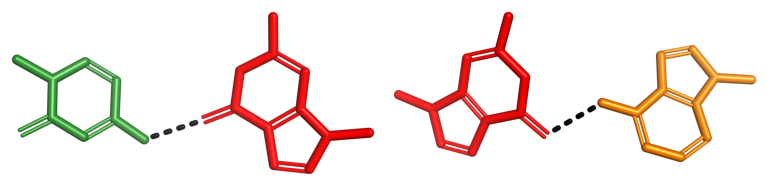

In [4]:
from PIL import Image, ImageOps

RENDERS = ROOT / "data" / "pymol" / "renders"
CROPPED = RENDERS / "cropped"
CROPPED.mkdir(parents=True, exist_ok=True)

EXAMPLES = [("S3C", "6Y0G", ("S2", "1534"), ("S2", "1600")),
            ("S3D", "8XSX", ("L5", "963"), ("L5", "2095"))]
TOOL_NAME = dict(zip(MATRIX_TOOLS, MATRIX_LABELS))


def autocrop(name, pad=8, thresh=246):
    src, dst = RENDERS / name, CROPPED / name
    im = Image.open(src).convert("RGB")
    grey = ImageOps.grayscale(im).point(lambda v: 255 if v < thresh else 0)
    box = grey.getbbox()
    if box:
        l, t, r, b = box
        im = im.crop((max(0, l - pad), max(0, t - pad),
                      min(im.width, r + pad), min(im.height, b + pad)))
    im.save(dst)
    return dst


@disk_cache
def example_records():
    pairsets, names = _load_all_pairsets(), _residue_names()
    out = {}
    for _, pdb, res1, res2 in EXAMPLES:
        key = tuple(sorted([_residue(*res1), _residue(*res2)]))
        bases = [names[pdb][f"{c}|{n}|{i}"] for c, n, i in key]
        calls = {t: "|".join(sorted(pairsets[t][pdb][key])) if key in pairsets[t].get(pdb, {})
                 else None for t in MATRIX_TOOLS}
        out[pdb] = (key, bases, calls)
    return out


def example_calls(pdb, res1, res2):
    key, bases, calls = example_records()[pdb]
    own = calls["parse"]
    opts = {canon(x) for x in own.split("|")}
    votes = {t: f for t in OTHER if calls[t] and (f := family({calls[t]})) is not None}
    assert "|" in own and len(set(votes.values())) > 1 and set(votes.values()) <= opts
    assert "dssr" in votes, "DSSR must give a full LW class"
    return key, bases, calls


def pair_name(bases, key):
    return "\u2013".join(f"{b}{n}" for b, (_, n, _) in zip(bases, key))


def call_table():
    cols = {}
    for panel, (_, pdb, r1, r2) in zip("CD", EXAMPLES):
        key, bases, calls = example_calls(pdb, r1, r2)
        (c1, n1, i1), (c2, n2, i2) = key
        cols[f"Panel {panel}"] = {"PDB": pdb,
                                  "residue 1": f"chain {c1}, {bases[0]}{n1}{i1}",
                                  "residue 2": f"chain {c2}, {bases[1]}{n2}{i2}",
                                  **{TOOL_NAME[t]: c or "not reported" for t, c in calls.items()}}
    return pd.DataFrame(cols)


CALLS = call_table()
print(CALLS.to_string())


def draw_example(ax, stem, pdb, res1, res2):
    ax.imshow(plt.imread(autocrop(f"{stem}.png")))
    ax.set_anchor("N")
    ax.set_xticks([]); ax.set_yticks([])
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(False)


def draw_cd(axes):
    for ax, (stem, pdb, r1, r2) in zip(axes, EXAMPLES):
        draw_example(ax, stem, pdb, r1, r2)


fig, axes = plt.subplots(1, 2, figsize=(6.0, 1.8))
draw_cd(axes)
fig.tight_layout()
save(fig, "figures/supplemental/figS3_CD_ambiguous_examples.png")
plt.show()


## Combined figure

saved 7.51 x 4.70 in; at 6.73 in wide the smallest text prints at 7.03 pt, height 4.21 in


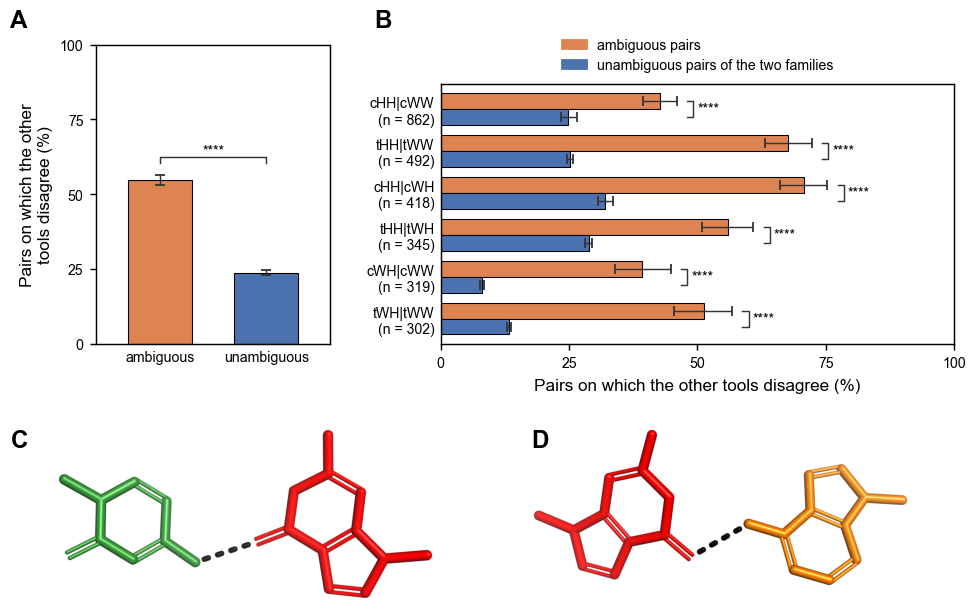

In [5]:
def restack_rows(fig, rows, gap_in=0.25, margin_in=0.05):
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    W, H = fig.get_size_inches()
    ft = lambda y_px: H - y_px / fig.dpi
    tops = [min(ft(a.get_tightbbox(r).y1) for a in row) for row in rows]
    bots = [max(ft(a.get_tightbbox(r).y0) for a in row) for row in rows]

    def row_of(y_ft):
        below = [i for i in range(len(rows)) if y_ft <= bots[i]]
        return min(below, key=lambda i: abs(tops[i] - y_ft)) if below else len(rows) - 1

    texts = [(t, row_of(ft(t.get_window_extent(r).y0))) for t in fig.texts]
    for t, i in texts:
        e = t.get_window_extent(r)
        tops[i], bots[i] = min(tops[i], ft(e.y1)), max(bots[i], ft(e.y0))
    gaps = list(gap_in) if np.iterable(gap_in) else [gap_in] * (len(rows) - 1)
    deltas, cursor = [], margin_in
    for i, (top, bot) in enumerate(zip(tops, bots)):
        deltas.append(cursor - top)
        cursor += bot - top + (gaps[i] if i < len(gaps) else 0)
    H2 = cursor + margin_in
    fig.set_size_inches(W, H2)
    conv = lambda y_frac, d: (H2 - (H - y_frac * H + d)) / H2
    for i, row in enumerate(rows):
        for a in row:
            p = a.get_position(original=True)
            a.set_position([p.x0, conv(p.y0, deltas[i]), p.width, p.height * H / H2],
                           which="both")
    for t, i in texts:
        x, y = t.get_position()
        t.set_position((x, conv(y, deltas[i])))


TEXT_PT, LETTER_PT = 7, 12


def set_uniform_text(fig, size=TEXT_PT):
    import matplotlib.text as mtext
    for t in fig.findobj(mtext.Text):
        if t.get_fontsize() >= LETTER_PT and t.get_fontweight() in ("bold", 700):
            continue
        t.set_fontsize(size)


plt.rcParams.update({"xtick.labelsize": 7, "ytick.labelsize": 7, "axes.labelsize": 8,
                     "legend.fontsize": 7})
FIG_W, FIG_H = 7.5, 8.0
fig = plt.figure(figsize=(FIG_W, FIG_H))
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]
ax_a = fig.add_axes(inch(0.75, 0.6, 1.8, 2.3))
ax_b = fig.add_axes(inch(3.4, 0.9, 3.95, 2.0))
ex = [fig.add_axes(inch(0.45 + k * 3.65, 3.9, 2.9, 1.6)) for k in range(2)]

draw_a(ax_a)
draw_b(ax_b)
draw_cd(ex)
set_uniform_text(fig)
enlarge_axis_labels(fig)

MARGIN_L = 0.012
inv = fig.transFigure.inverted()
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
box = lambda a: a.get_tightbbox(renderer).transformed(inv)
top_ab = max(box(ax_a).y1, box(ax_b).y1)
fig.text(MARGIN_L, top_ab + 0.004, "A", fontsize=LETTER_PT, fontweight="bold", ha="left", va="bottom")
fig.text(box(ax_b).x0, top_ab + 0.004, "B", fontsize=LETTER_PT, fontweight="bold", ha="left", va="bottom")
for ax, s in zip(ex, "CD"):
    fig.text(MARGIN_L if s == "C" else ax.get_position().x0, ax.get_position().y1, s,
             fontsize=LETTER_PT, fontweight="bold", ha="left", va="top")

restack_rows(fig, [[ax_a, ax_b], ex], gap_in=0.30)

def _ensure_print_pt(fig, min_pt=7.0, page_in=6.73, pad=0.08):
    import matplotlib.text as mtext
    texts = [t for t in fig.findobj(mtext.Text) if t.get_visible() and t.get_text().strip()]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        smallest = min(t.get_fontsize() for t in texts) / shrink
        if smallest >= min_pt - 1e-3:
            break
        for t in texts:
            t.set_fontsize(t.get_fontsize() * min_pt / smallest * 1.005)
    print(f"saved {bb.width + 2 * pad:.2f} x {bb.height + 2 * pad:.2f} in; at {page_in} in wide "
          f"the smallest text prints at {smallest:.2f} pt, height {(bb.height + 2 * pad) / shrink:.2f} in")


_ensure_print_pt(fig)

save(fig, "figures/supplemental/figS3.png")
plt.show()
